# Lab: Exploratory Decision Trees — Breast Cancer Wisconsin Dataset

**Objective:** Build intuition for how a Decision Tree Classifier actually behaves —
not just how to call `.fit()`. You will explore split criteria (Gini vs Entropy),
tree depth, and other hyperparameters to find the configuration that generalizes best.

**Dataset:** Breast Cancer Wisconsin (Diagnostic) — 569 samples, 30 numeric features,
binary target (malignant / benign), built into `sklearn.datasets`.

**How this notebook works:** Most cells run as-is. Cells marked **`# TODO`** are where
*you* make a decision, change a value, or write a short interpretation — the notebook
will still run without them, but you won't learn much by skipping them.

---
## 1. Setup & Dataset

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
)

sns.set_style("whitegrid")
np.random.seed(42)


RANDOM_STATE = 42

data.data → actual input feature values

data.feature_names → names of the input features

data.target → class labels

data.target_names → names of the classes

In [ ]:
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")   # 0 = malignant, 1 = benign

print("Shape:", X.shape)
print("Classes:", dict(zip(data.target_names, [0, 1])))   #zip(names, labels)
print(y.value_counts())   #how many samples belong to each count
X.head()

Shape: (569, 30)
Classes: {np.str_('malignant'): 0, np.str_('benign'): 1}
target
1    357
0    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


---
## 2. Quick EDA

It creates a bar graph showing how many malignant and benign samples are present.

It prints the percentage of malignant and benign samples.

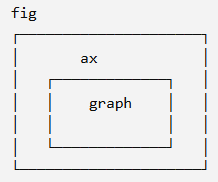

1 = benign     → 357 samples

0 = malignant  → 212 samples

Total          → 569 samples

So:

Benign proportion= 357/569 = .627
	​

Malignant proportion= 212/569 = .373


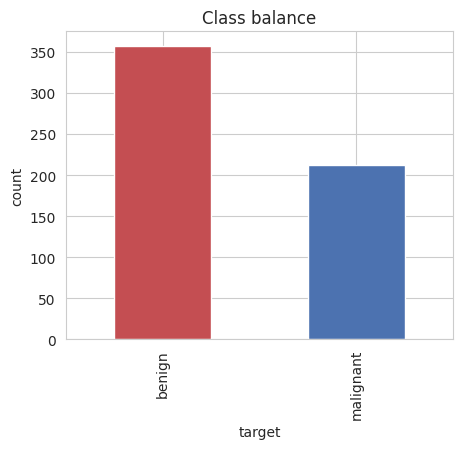

target
1    0.627
0    0.373
Name: proportion, dtype: float64


In [ ]:
fig, ax = plt.subplots(figsize=(5, 4))
y.value_counts().rename({0: 'malignant', 1: 'benign'}).plot(kind='bar', ax=ax, color=['#c44e52', '#4c72b0'])
ax.set_title("Class balance")
ax.set_ylabel("count")
plt.show()

print(y.value_counts(normalize=True).round(3)) #calculates the proportion of each class instead of the actual count.

**TODO (reflection):** Is this dataset balanced or imbalanced? Keep this in mind —
you'll come back to it in Section 8 when judging whether a model's accuracy number
alone tells the full story.

*Your answer:* Mildly imbalanced — 357 benign (62.7%) vs 212 malignant (37.3%). This matters because a classifier that always predicted
"benign" would already score ~63% accuracy without learning anything, so any
accuracy number in this notebook should be read as "gain over that ~63% floor,"
not against a 50% baseline. It's not severe enough to require resampling or
class weighting, but it's why every accuracy figure in this lab is paired with
a confusion matrix or classification report — accuracy alone can look high
while still hiding a lopsided error pattern

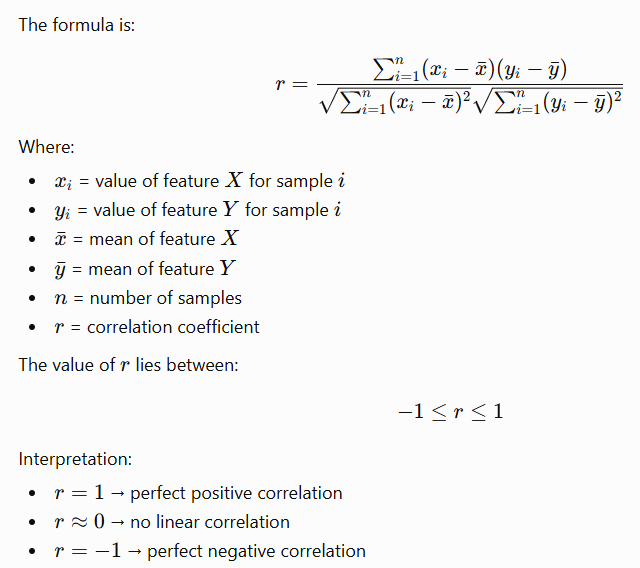

If correlation is close to 0: there is little or no linear relationship between the two features.

If correlation is positive: the features move in the same direction — as one increases, the other tends to increase.

If correlation is negative: the features move in opposite directions — as one increases, the other tends to decrease.

Also, the closer the value is to +1 or -1, the stronger the relationship.

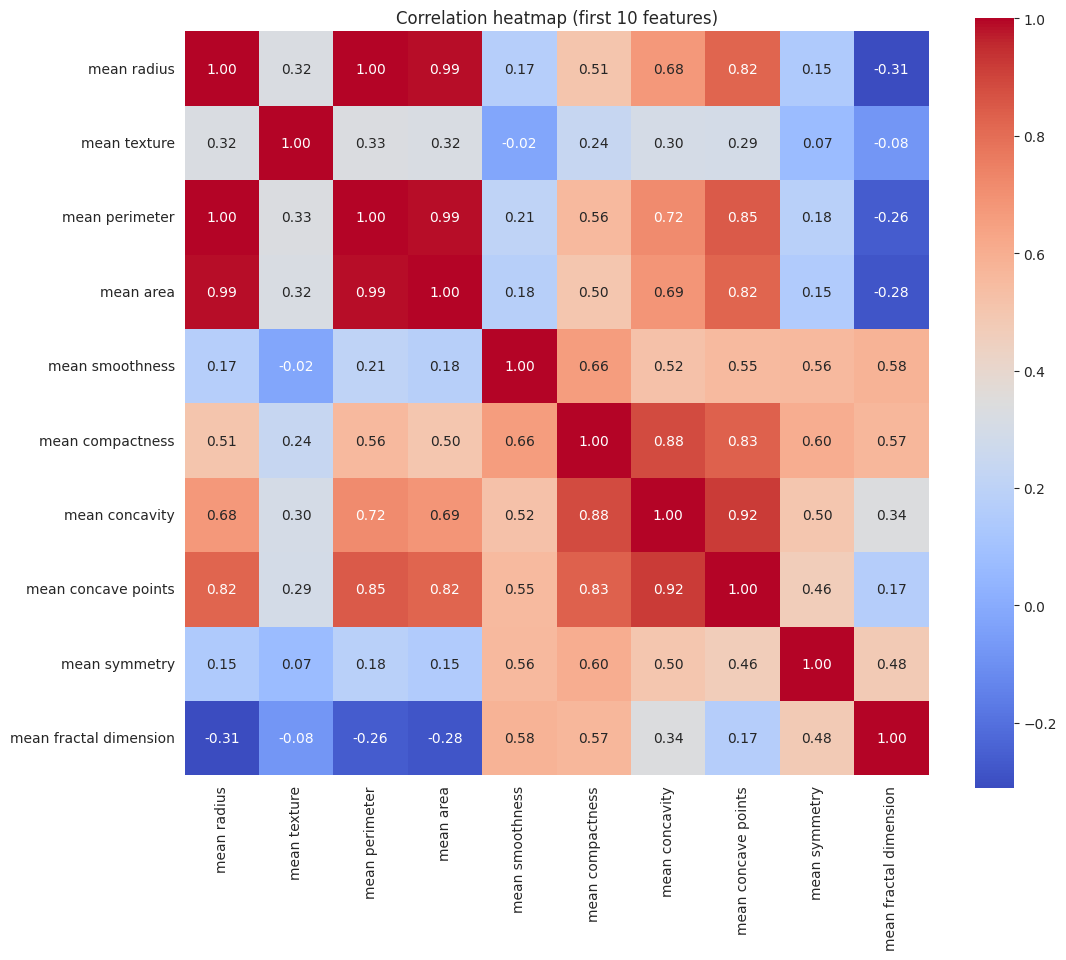

In [ ]:
plt.figure(figsize=(12, 10))
corr = X.iloc[:, :10]  # first 10 features, full 30x30 is unreadable   #integer-location based indexing.
sns.heatmap(corr.corr(), annot=True, fmt=".2f", cmap="coolwarm", square=True)
plt.title("Correlation heatmap (first 10 features)")
plt.show()

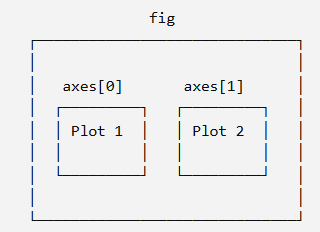

We use the KDE plot to see whether the feature values are different for malignant and benign cases.

Less overlap between the two curves means the feature can distinguish the two classes better; more overlap means classification using that feature is more difficult.

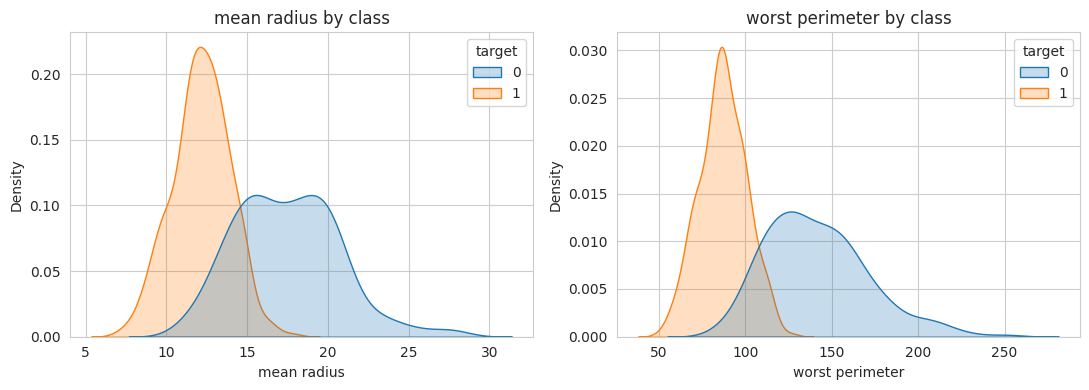

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, feat in zip(axes, ['mean radius', 'worst perimeter']): #hue='target' tells Seaborn to separate the KDE curves based on the target class.
    sns.kdeplot(data=X.assign(target=y), x=feat, hue='target', fill=True, ax=ax, common_norm=False)    #Kernel Density Estimation plot.  Common_norm=False: Normalize the KDE distribution of each class separately.
    ax.set_title(f"{feat} by class")   #The f indicates an f-string.
plt.tight_layout()
plt.show()

---
## 3. Baseline Model

Train test split first, then fit a plain, default-parameter `DecisionTreeClassifier`.
Everything after this cell is measured against this baseline.

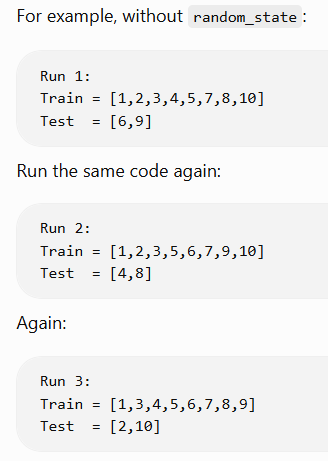     With random_state                             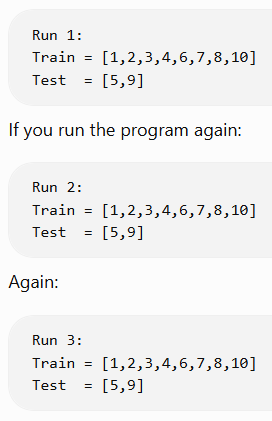

Original dataset
Benign     ≈ 63%
Malignant  ≈ 37%

Training set
Benign     ≈ 63%
Malignant  ≈ 37%

Test set
Benign     ≈ 63%
Malignant  ≈ 37%

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (455, 30)  Test: (114, 30)


In [ ]:
baseline_model = DecisionTreeClassifier(random_state=RANDOM_STATE)
baseline_model.fit(X_train, y_train)
baseline_pred = baseline_model.predict(X_test)

baseline_acc = accuracy_score(y_test, baseline_pred)
print("Baseline accuracy:", round(baseline_acc, 4))
print("Baseline tree depth:", baseline_model.get_depth(), " | leaves:", baseline_model.get_n_leaves())
print()
print(classification_report(y_test, baseline_pred, target_names=data.target_names))

Baseline accuracy: 0.9123
Baseline tree depth: 7  | leaves: 19

              precision    recall  f1-score   support

   malignant       0.85      0.93      0.89        42
      benign       0.96      0.90      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114



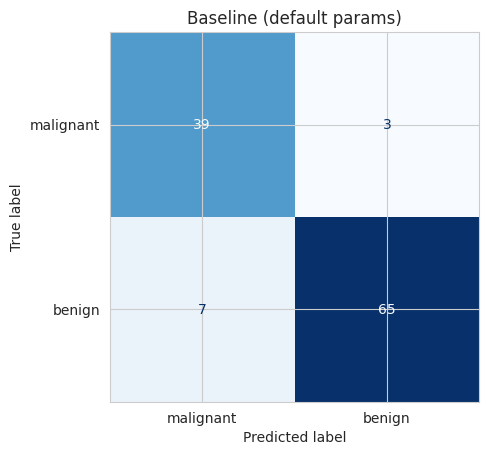

array([[39,  3],
       [ 7, 65]])

In [ ]:
def plot_confusion(model, X_te, y_te, title):
    """Reusable confusion matrix plotter — used throughout the rest of the lab."""
    pred = model.predict(X_te)
    cm = confusion_matrix(y_te, pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=data.target_names)
    disp.plot(cmap="Blues", colorbar=False)
    plt.title(title)
    plt.show()
    return cm

plot_confusion(baseline_model, X_test, y_test, "Baseline (default params)")

---
## 4. Gini vs Entropy

Same tree, same split, only the impurity measure changes.

In [ ]:
criterion_results = {}
for c in ['gini', 'entropy']:
    m = DecisionTreeClassifier(criterion=c, random_state=RANDOM_STATE)
    m.fit(X_train, y_train)
    acc = accuracy_score(y_test, m.predict(X_test))
    criterion_results[c] = acc
    print(f"{c:10s} -> accuracy = {acc:.4f}, depth = {m.get_depth()}")    #{c:10s} This means: Display the string c using a field width of 10 characters.

gini       -> accuracy = 0.9123, depth = 7
entropy    -> accuracy = 0.9123, depth = 6


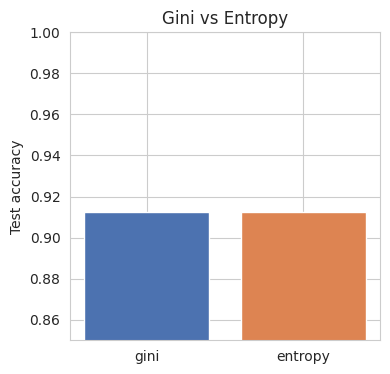

In [ ]:
plt.figure(figsize=(4, 4))
plt.bar(criterion_results.keys(), criterion_results.values(), color=['#4c72b0', '#dd8452'])
plt.ylim(0.85, 1.0)   #Y-axis limits.
plt.ylabel("Test accuracy")
plt.title("Gini vs Entropy")
plt.show()

**TODO (reflection):** Gini and Entropy are both impurity measures but computed
differently (Gini: `1 - sum(p_i^2)`, Entropy: `-sum(p_i * log2(p_i))`). Did they produce
the same accuracy here? If so, does that mean they always pick the same splits — or just
that this dataset doesn't stress the difference? Write 2-3 sentences.

*Your answer:* Yes — both hit 0.9123 test accuracy, but the trees aren't identical
underneath: gini grew to depth 7 while entropy stopped at depth 6, so they didn't
pick exactly the same splits, they just converged on the same final accuracy. This
isn't because gini and entropy always agree — it's because this dataset has strong,
clean separating features (like worst radius), so almost any reasonable impurity
measure ranks the best candidate splits the same way. On a messier or more
imbalanced dataset with weaker features, gini and entropy would be more likely to
diverge on close calls.

---
## 5. Depth Exploration — the core overfitting curve

Sweep `max_depth` from 1 to 20 and track **train** and **test** accuracy separately.
This is the single most important plot in the lab.

For a Decision Tree using the default criterion, which depth gives the best accuracy, and where does overfitting start?

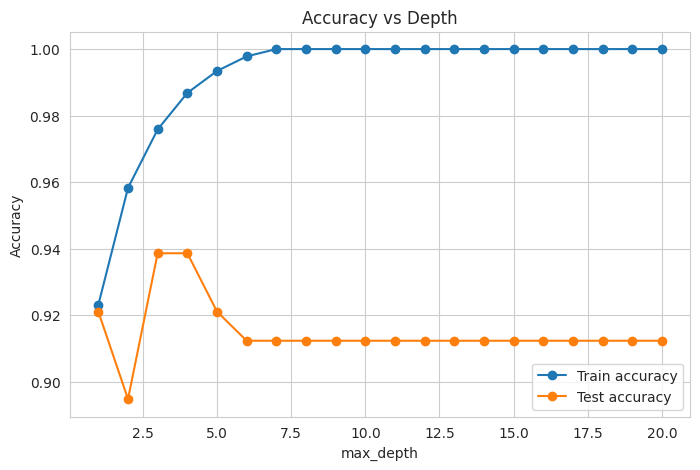

In [ ]:
depths = range(1, 21)
train_accs, test_accs = [], []

for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE)   #gini by default
    m.fit(X_train, y_train)
    train_accs.append(accuracy_score(y_train, m.predict(X_train)))
    test_accs.append(accuracy_score(y_test, m.predict(X_test)))

plt.figure(figsize=(8, 5))
plt.plot(depths, train_accs, marker='o', label='Train accuracy')
plt.plot(depths, test_accs, marker='o', label='Test accuracy')
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Accuracy vs Depth")
plt.legend()
plt.show()


At depth 1, both training and test accuracy are around 0.92, so the tree is very simple and may be underfitting.

At depth 2, training accuracy improves to about 0.958, but test accuracy actually drops to about 0.895, so that depth is not good.

At depth 3 and 4, the test accuracy reaches its highest value, about 0.939, while training accuracy is also high, around 0.976–0.987. This is the best region because the model performs well on unseen data.

After depth 4, training accuracy keeps increasing, eventually reaching 1.00 around depth 7, but test accuracy falls to about 0.912 and stays there. This means the tree is fitting the training data perfectly but is not improving on unseen test data, which indicates overfitting.

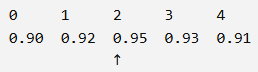

In [ ]:
best_depth_by_test = depths[int(np.argmax(test_accs))]  #returns the index position of the largest value.
print("Depth with highest test accuracy:", best_depth_by_test, "->", round(max(test_accs), 4))
print("Train accuracy at that depth:", round(train_accs[best_depth_by_test - 1], 4))

Depth with highest test accuracy: 3 -> 0.9386
Train accuracy at that depth: 0.9758


---
## 6. Accuracy vs Depth, split by Criterion

Same sweep, but gini and entropy plotted separately — does the optimal depth shift?

If I also compare Gini and Entropy, which combination of criterion + depth gives the best test accuracy?  
For each criterion (gini and entropy), the code calculates the test accuracy for every depth from 1 to 20 and stores those accuracies.

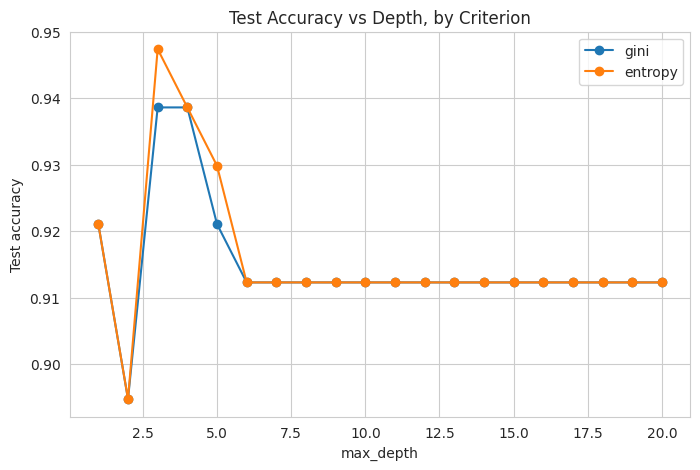

Best combo so far: entropy at depth 3


In [ ]:
depth_criterion_results = {}
for c in ['gini', 'entropy']:
    accs = []
    for d in depths:
        m = DecisionTreeClassifier(criterion=c, max_depth=d, random_state=RANDOM_STATE)
        m.fit(X_train, y_train)
        accs.append(accuracy_score(y_test, m.predict(X_test)))
    depth_criterion_results[c] = accs

plt.figure(figsize=(8, 5))
for c, accs in depth_criterion_results.items():
    plt.plot(depths, accs, marker='o', label=c)
plt.xlabel("max_depth")
plt.ylabel("Test accuracy")
plt.title("Test Accuracy vs Depth, by Criterion")
plt.legend()
plt.show()

# TODO: find the best (criterion, depth) pair from this plot and print it below.
best_c = max(depth_criterion_results, key=lambda c: max(depth_criterion_results[c]))
best_d = depths[int(np.argmax(depth_criterion_results[best_c]))]
print("Best combo so far:", best_c, "at depth", best_d)

---
## 7. Pruning — cost-complexity as an alternative to early stopping

`max_depth` stops the tree from growing past a certain point. Cost-complexity
pruning does the opposite: grow the full tree, then trim it back afterward
using `ccp_alpha`. Same goal (control overfitting), different mechanism.

ccp_alpha: to control how much pruning should be applied to the tree so that unnecessary branches are removed and overfitting can be reduced.

ccp_alpha = 0
→ almost no pruning
→ large tree
→ possible overfitting

ccp_alpha = 0.005
→ some branches removed
→ simpler tree
→ may generalize better

ccp_alpha = 0.1
→ too many branches removed
→ tree becomes too simple
→ possible underfitting

There is no fixed number of ccp_alpha values. The algorithm automatically calculates several possible pruning values based on the structure of the fully grown tree.

alpha = 0.000 → almost full tree

alpha = 0.002 → slightly pruned tree

alpha = 0.004 → more pruning

alpha = 0.007 → still more pruning

ccp_alpha small
→ less pruning
→ complex tree
→ possible overfitting

ccp_alpha moderate
→ useful pruning
→ better generalization

ccp_alpha very large
→ excessive pruning
→ tree too simple
→ underfitting

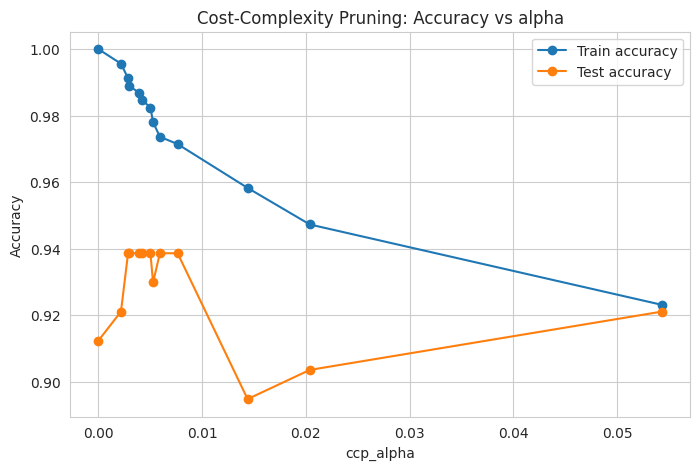

In [ ]:
pruning_path = DecisionTreeClassifier(random_state=RANDOM_STATE).cost_complexity_pruning_path(X_train, y_train)
#Build the tree and tell the different ccp_alpha values at which branches can be removed
ccp_alphas = pruning_path.ccp_alphas[:-1]  # drop the trivial single-node alpha
#[0.0000, 0.0021, 0.0035, 0.0068, 0.0124, 0.0450]

ccp_train_accs, ccp_test_accs = [], []
for a in ccp_alphas:
    m = DecisionTreeClassifier(random_state=RANDOM_STATE, ccp_alpha=a)
    m.fit(X_train, y_train)
    ccp_train_accs.append(accuracy_score(y_train, m.predict(X_train)))
    ccp_test_accs.append(accuracy_score(y_test, m.predict(X_test)))

plt.figure(figsize=(8, 5))
plt.plot(ccp_alphas, ccp_train_accs, marker='o', label='Train accuracy')
plt.plot(ccp_alphas, ccp_test_accs, marker='o', label='Test accuracy')
plt.xlabel("ccp_alpha")
plt.ylabel("Accuracy")
plt.title("Cost-Complexity Pruning: Accuracy vs alpha")
plt.legend()
plt.show()


When ccp_alpha is close to 0, there is almost no pruning, so the tree is very complex:

the training accuracy is about 1.00, while the test accuracy is only about 0.912, indicating overfitting.

As ccp_alpha increases to approximately 0.003–0.008, some unnecessary branches are removed; the training accuracy decreases slightly to around 0.97–0.99, while the test accuracy improves to its highest value of about 0.939, so this is the good pruning region.

When ccp_alpha increases further, around 0.014 and above, too many branches are removed and the test accuracy drops to about 0.895, indicating underfitting due to excessive pruning.

Therefore, for this graph, a moderate ccp_alpha around 0.003–0.008 is preferable, while values that are too small may cause overfitting and values that are too large may cause underfitting.

**TODO (reflection):** `ccp_alpha` prunes a fully-grown tree after the fact,
instead of stopping it early like `max_depth` does. Compare this curve's shape
to the depth curve in Section 5 — same story, or different?

*Your answer:* Similar peak, different tail. Both curves peak at almost the
same test accuracy (approx. 0.94) at low complexity, so as a way to *find* the
best model, depth and pruning agree. But after the peak they diverge: the depth
curve plateaus flat at 0.913 once the tree is deep enough to overfit — extra
depth stops mattering. The pruning curve instead dips to a trough (approx.
0.895) before climbing back up as alpha increases further, because large
ccp_alpha values collapse the tree down to just a couple of leaves — that's
severe underfitting, a different failure mode than depth's "stuck overfit,"
not a continuation of the same trend.

---
## 8. Confusion Matrix Deep-Dive

Compare confusion matrices at a **shallow**, **near-optimal**, and **overly deep** tree
using the `plot_confusion()` function defined back in Section 3.

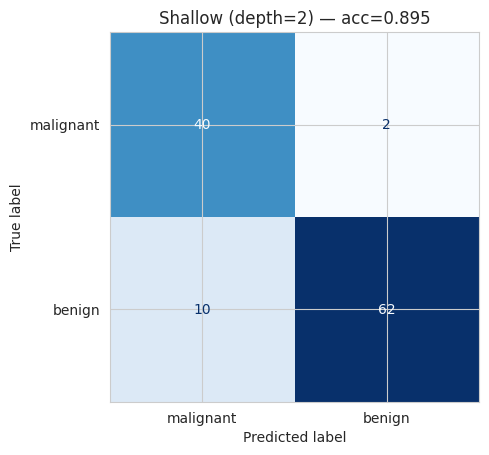

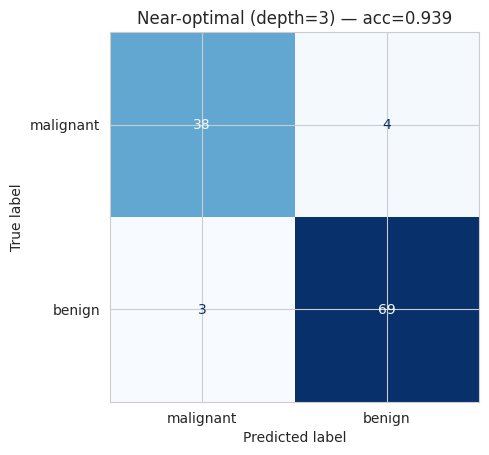

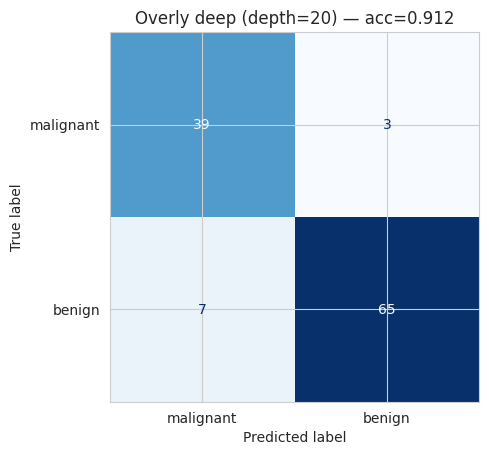

In [ ]:
shallow_model = DecisionTreeClassifier(max_depth=2, random_state=RANDOM_STATE).fit(X_train, y_train)
best_model_depth_only = DecisionTreeClassifier(max_depth=best_depth_by_test, random_state=RANDOM_STATE).fit(X_train, y_train)
deep_model = DecisionTreeClassifier(max_depth=20, random_state=RANDOM_STATE).fit(X_train, y_train)

for m, label in [(shallow_model, "Shallow (depth=2)"),
                  (best_model_depth_only, f"Near-optimal (depth={best_depth_by_test})"),
                  (deep_model, "Overly deep (depth=20)")]:
    acc = accuracy_score(y_test, m.predict(X_test))
    plot_confusion(m, X_test, y_test, f"{label} — acc={acc:.3f}")


**TODO (reflection):** The accuracy numbers alone might look similar across these
three models. Do the confusion matrices tell a more interesting story than the
accuracy number does? Specifically: comparing the near-optimal tree to the
overly-deep one, which error type increases as depth grows past the sweet spot?
And separately — how does the shallow tree's error trade-off differ from both?

*Your answer:* Yes — accuracy alone (0.895 / 0.939 / 0.912) hides very different
error profiles. Comparing near-optimal (depth=3) to overly-deep (depth=20):
missed cancers (malignant→benign) stay roughly flat (4→3), while false alarms
(benign→malignant) roughly double (3→7) — so past the sweet spot, overfitting
here mainly inflates false alarms, not missed cancers, which is the opposite of
what students often guess by default.

The shallow tree (depth=2) tells a different story: it has the *fewest* missed
cancers of all three models (2) but the *most* false alarms (10). Despite its
lowest accuracy, it isn't uniformly "worse" — it trades errors in the opposite
direction from overfitting. This is underfitting, a different failure mode, and
it happens to trade errors the opposite way on this dataset.

Takeaway: "deeper tree = more of the dangerous error" is not what happened here.
Depth past the sweet spot increased false alarms specifically, while the
shallow model's low accuracy came from a separate, opposite trade-off.

---
## 9. Grid Search

Search jointly over criterion and depth using
5-fold cross-validation on the training set.

In [ ]:
param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [3, 4, 5, 6, 7, 8, None],

}  #None: the Decision Tree is allowed to grow until its normal stopping conditions are reached, instead of being stopped at a fixed depth.

#This grid has 2 criteria × 7 depths = 14 combinations. With `cv=5`, that means
#`GridSearchCV` will fit 14 × 5 = 70 models total — which is why this cell takes
#noticeably longer to run than any single `.fit()` call earlier in the lab.
grid_search = GridSearchCV(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_grid,
    cv=5,      #Each of these 14 combinations is trained and tested 5 different times using 5 different folds of the training data.
    scoring='accuracy',
    n_jobs=-1,   #all available CPU cores on your computer to run the model fits in parallel.
)
grid_search.fit(X_train, y_train)

print("Best CV params:", grid_search.best_params_)
print("Best CV accuracy:", round(grid_search.best_score_, 4))

Best CV params: {'criterion': 'gini', 'max_depth': 4}
Best CV accuracy: 0.9385


GridSearchCV automatically provides standard attributes such as:

grid_search.fit(X_train, y_train)

grid_search.best_params_ → best parameter combination

grid_search.best_score_ → best mean cross-validation score

grid_search.best_estimator_ → the actual best trained model

Grid-search model — held-out test accuracy: 0.9386
Baseline (Section 4) test accuracy:         0.9123
Your manual best from Section 6:             entropy depth 3


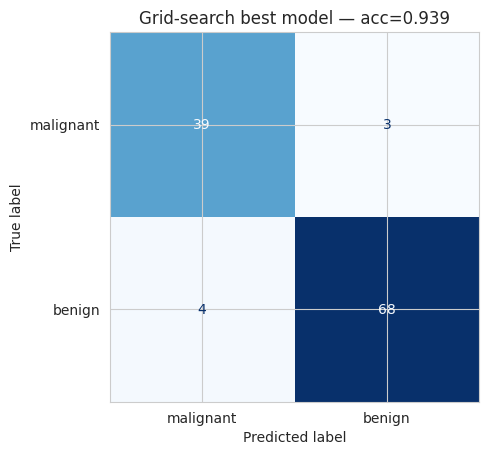

array([[39,  3],
       [ 4, 68]])

In [ ]:
best_model = grid_search.best_estimator_      #Take the model with the best hyperparameter combination found during Grid Search and store it in the variable best_model.
best_test_acc = accuracy_score(y_test, best_model.predict(X_test))

print("Grid-search model — held-out test accuracy:", round(best_test_acc, 4))
print("Baseline (Section 4) test accuracy:        ", round(baseline_acc, 4))
print("Your manual best from Section 6:            ", best_c, "depth", best_d)

plot_confusion(best_model, X_test, y_test, f"Grid-search best model — acc={best_test_acc:.3f}")


**TODO (reflection):** Did GridSearchCV beat your manual exploration from
Sections 4-7? If not, why might that be, given cross-validation vs a single
train/test split?

*Your answer:* No — GridSearchCV picked `gini, depth=4` (test acc 0.9386),
essentially tied with the manual best (`entropy, depth=3`, test acc 0.9386).
That's expected: the manual best was chosen using one single train/test split,
which can get lucky; GridSearchCV's 5-fold CV score is a more reliable estimate
of generalization, not necessarily a higher one. On a clean dataset like this,
both approaches land near the same ceiling.

---
## 10. Bonus — Feature Importance & Tree Visualization

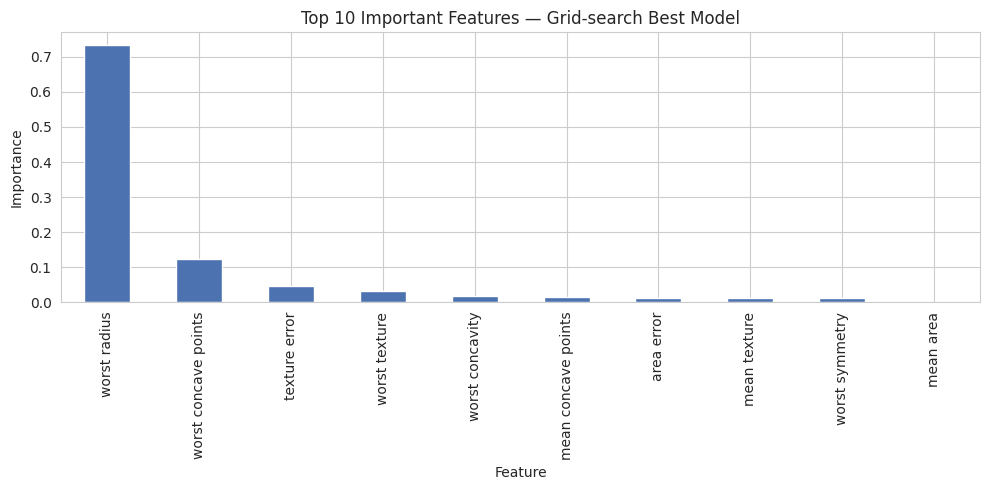

,Feature,Importance
20,worst radius,0.733548
27,worst concave points,0.122028
11,texture error,0.045785
21,worst texture,0.032319
26,worst concavity,0.017161
7,mean concave points,0.013327
13,area error,0.012704
1,mean texture,0.011846
28,worst symmetry,0.011282
3,mean area,0.000000


In [ ]:
importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': best_model.feature_importances_   #returns the importance score of every input feature used by the trained Decision Tree.
}).sort_values('Importance', ascending=False)

importance.head(10).plot(x='Feature', y='Importance', kind='bar', figsize=(10, 5), legend=False, color='#4c72b0')
plt.title("Top 10 Important Features — Grid-search Best Model")
plt.ylabel("Importance")
plt.tight_layout()
plt.show()

importance.head(10)

Visualize the final best Decision Tree selected by GridSearchCV

**plot_tree()** is a standard scikit-learn function used to draw a trained Decision Tree.

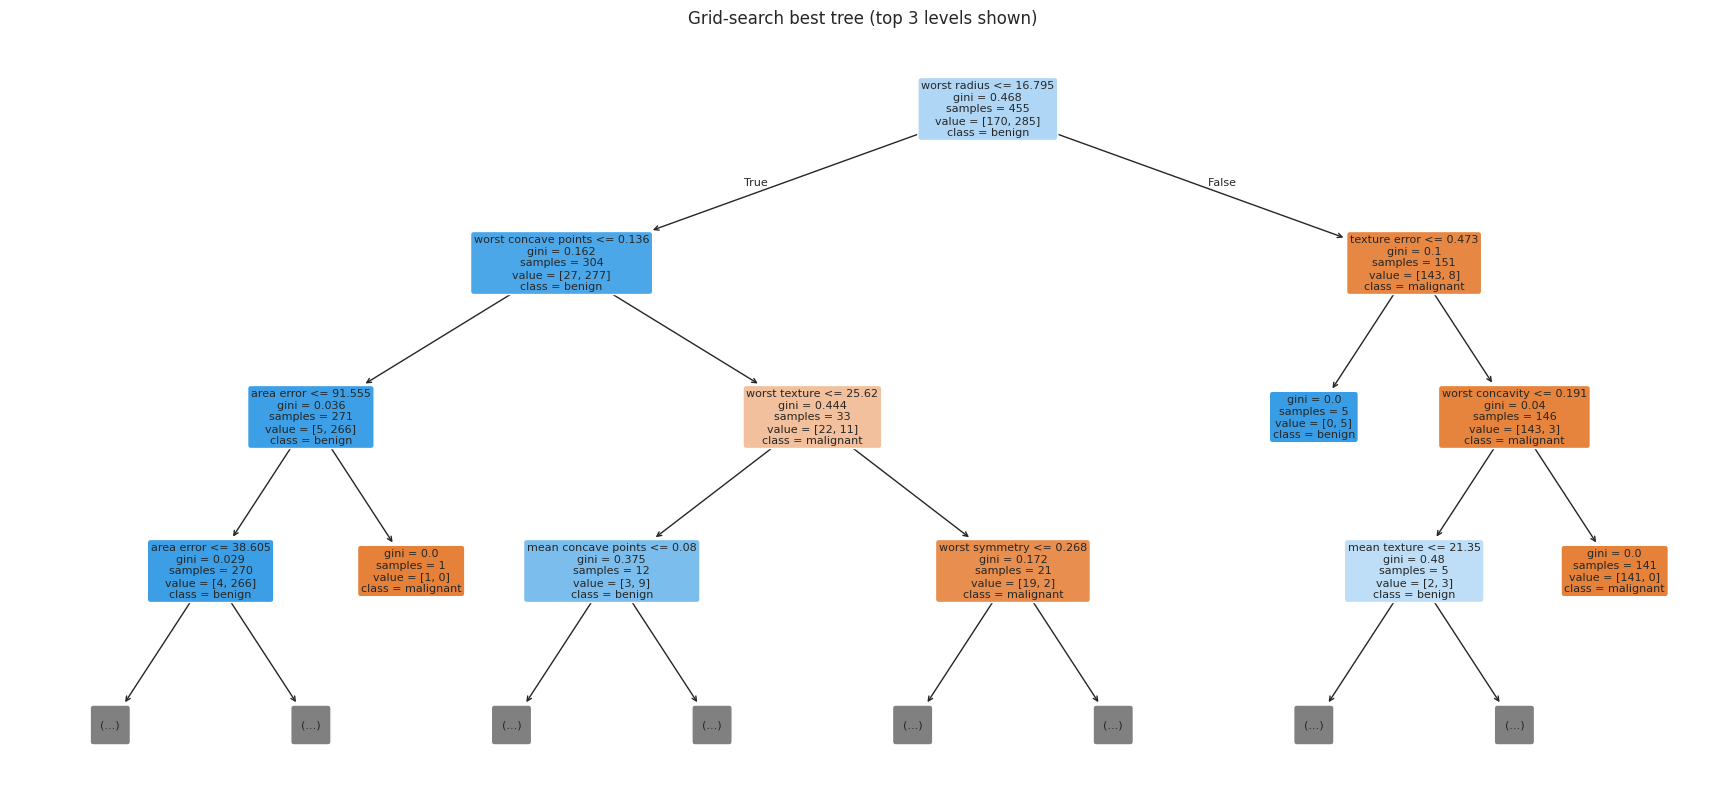

In [ ]:
plt.figure(figsize=(22, 10))
plot_tree(
    best_model,
    feature_names=X.columns,
    class_names=data.target_names,
    filled=True,
    rounded=True,   #This makes the node boxes have rounded corners.
    fontsize=8,
    max_depth=3,   # show only the top 3 levels — full tree is unreadable
)
plt.title("Grid-search best tree (top 3 levels shown)")
plt.show()


**TODO (reflection):** Does the root-node split use one of the top-3 features
from the importance bar chart above? It should — explain in one sentence why
that's not a coincidence.

*Your answer:* Yes — the root splits on `worst radius`, the #1 feature. This
isn't a coincidence because feature importance is based on how much each
feature reduces impurity across the tree, and the root split acts on 100% of
the training samples — the biggest impurity reduction available anywhere in
the tree — so the feature chosen there is almost guaranteed to end up with the
highest total importance.

---
## 11. Reflection / Write-up

Answer each of these in 2-4 sentences.

1. **Which hyperparameter had the biggest effect on overfitting — depth, criterion or ccp_alpha?** What made you pick that one?

   *Your answer:* — *(replace this line)*

2. **Did Gini and Entropy ever meaningfully disagree** — on accuracy, depth, or which
   feature got picked at the root? Or did they behave almost identically throughout?

   *Your answer:* — *(replace this line)*

3. **What would you tell someone who just maximizes test-set accuracy blindly**, without
   looking at confusion matrices or train/test gaps? Use something you saw in this lab
   as evidence.

   *Your answer:* — *(replace this line)*

4. **You controlled tree complexity three different ways in this lab** — `max_depth`
   (Section 5), `ccp_alpha` (Section 7), and `GridSearchCV`'s cross-validated search
   (Section 9).

   a) What's the key difference between how `max_depth` and `ccp_alpha` arrive at
      a simpler tree?

   b) Suppose your manual best from Section 6 scores higher on the test set than
      GridSearchCV's winner. Does that mean the manual pick is a genuinely better
      model? What does this tell you about comparing models this way?

   *Your answer:* — *(replace this line)*